# Simple Classifier met PyTorch

In deze notebook bouwen we dezelfde classifier opnieuw, maar nu met PyTorch.

Het doel van classifier:

Onderzoeken hoe een eenvoudig PyTorch-model met één neuron leert om zes fictieve voorbeelden op basis van twee numerieke kenmerken in twee vooraf gedefinieerde groepen in te delen.

Leerdoelen:
- herkennen welke onderdelen hetzelfde blijven;
- zien welke taken PyTorch van ons overneemt;
- voorbereiden op een klein neuraal netwerk en later de House Price Predictor.

In [7]:
import torch
print(torch.__version__)

2.14.0+cpu


## 1. Trainingsdata als tensors

In de eerdere classifier gebruikten we een gewone Python-list.

PyTorch werkt vooral met **tensors**.

Een tensor is een datastructuur voor getallen waarmee PyTorch efficiënt kan rekenen.

In [8]:
training_features = torch.tensor([
    [160, 55],
    [165, 60],
    [170, 65],
    [180, 80],
    [185, 85],
    [190, 90]
], dtype=torch.float32)

training_labels = torch.tensor([
    [0],
    [0],
    [0],
    [1],
    [1],
    [1]
], dtype=torch.float32)

print(training_features)
print()
print(training_labels)

tensor([[160.,  55.],
        [165.,  60.],
        [170.,  65.],
        [180.,  80.],
        [185.,  85.],
        [190.,  90.]])

tensor([[0.],
        [0.],
        [0.],
        [1.],
        [1.],
        [1.]])


In [9]:
print(training_features)
print()
print(training_labels)

print()
print("Vorm features:", training_features.shape)
print("Vorm labels:", training_labels.shape)

tensor([[160.,  55.],
        [165.,  60.],
        [170.,  65.],
        [180.,  80.],
        [185.,  85.],
        [190.,  90.]])

tensor([[0.],
        [0.],
        [0.],
        [1.],
        [1.],
        [1.]])

Vorm features: torch.Size([6, 2])
Vorm labels: torch.Size([6, 1])


## 2. Het model

We beginnen met één neuron.

Het neuron krijgt twee features als input:

- lichaamslengte
- lichaamsgewicht

Het neuron heeft voor iedere input een weight en daarnaast een bias.

De berekening is:

**output = lichaamslengte × weight₁ + lichaamsgewicht × weight₂ + bias**

In PyTorch gebruiken we hiervoor `nn.Linear(2, 1)`:

- `2` = aantal input-features
- `1` = aantal outputs

In [10]:
from torch import nn

model = nn.Linear(2, 1)

print(model)

Linear(in_features=2, out_features=1, bias=True)


## 3. Weights en bias bekijken

PyTorch heeft voor `nn.Linear(2, 1)` automatisch de modelparameters aangemaakt:

- twee weights, één voor iedere input-feature;
- één bias.

Deze waarden zijn op dit moment nog beginwaarden. Ze zijn nog niet geleerd uit de trainingsdata.

In [11]:
print("Weights:")
print(model.weight)

print()

print("Bias:")
print(model.bias)

Weights:
Parameter containing:
tensor([[-0.0508,  0.4039]], requires_grad=True)

Bias:
Parameter containing:
tensor([-0.0104], requires_grad=True)


## 4. Forward propagation

Bij forward propagation sturen we de features door het model.

Het model gebruikt zijn huidige weights en bias om een output te berekenen.

Voor één voorbeeld gebeurt in ons huidige model:

**output = lichaamslengte × weight₁ + lichaamsgewicht × weight₂ + bias**

Er worden tijdens deze stap nog geen weights of bias aangepast.

In [12]:
voorbeeld = torch.tensor([[160, 55]], dtype=torch.float32)

output = model(voorbeeld)

print("Input:")
print(voorbeeld)

print()

print("Output:")
print(output)

Input:
tensor([[160.,  55.]])

Output:
tensor([[14.0834]], grad_fn=<AddmmBackward0>)


## 5. Activation function: sigmoid

Het model produceert eerst een ruwe output.

Voor binaire classificatie kunnen we de sigmoid-functie gebruiken om deze
ruwe output om te zetten naar een waarde tussen 0 en 1.

- waarde dicht bij 0 → model neigt naar klasse 0
- waarde dicht bij 1 → model neigt naar klasse 1
- 0.5 vormt de beslissingsgrens

De sigmoid verandert de weights en bias niet.

In [13]:
kans = torch.sigmoid(output)

print("Ruwe output:", output)
print("Na sigmoid:", kans)

Ruwe output: tensor([[14.0834]], grad_fn=<AddmmBackward0>)
Na sigmoid: tensor([[1.0000]], grad_fn=<SigmoidBackward0>)


In [14]:
if kans >= 0.5:
    voorspelling = 1
else:
    voorspelling = 0

print("Voorspelling:", voorspelling)

Voorspelling: 1


## 6. Loss

Tijdens de training moet het model weten hoe goed of slecht de voorspelling is.

In onze classifier zonder framework gebruikten we:

**fout = juiste_antwoord - voorspelling**

Bij een neuraal netwerk gebruiken we een **loss-functie**.

Voor deze binaire classifier gebruiken we Binary Cross Entropy (BCE).

De loss vergelijkt de voorspelde waarde na sigmoid met het juiste label.

Een kleine loss betekent dat de voorspelling goed bij het juiste antwoord past.
Een grote loss betekent dat de voorspelling slecht bij het juiste antwoord past.

In [15]:
juiste_antwoord = torch.tensor([[0.0]])

loss_functie = nn.BCELoss()

loss = loss_functie(kans, juiste_antwoord)

print("Voorspelde waarde:", kans)
print("Juiste antwoord:", juiste_antwoord)
print("Loss:", loss)

Voorspelde waarde: tensor([[1.0000]], grad_fn=<SigmoidBackward0>)
Juiste antwoord: tensor([[0.]])
Loss: tensor(14.1506, grad_fn=<BinaryCrossEntropyBackward0>)


## 7. Het ongetrainde model controleren

De weights en bias van het model zijn willekeurig geïnitialiseerd.

Daarom controleren we eerst hoe het ongetrainde model voorspelt voor alle trainingsvoorbeelden.

Het model voert voor alle voorbeelden forward propagation uit:

**features → Linear → ruwe output → sigmoid → voorspelling**

We vergelijken de voorspelling met het juiste label.

De weights en bias worden in deze stap nog niet aangepast.

In [16]:
ruwe_outputs = model(training_features)

kansen = torch.sigmoid(ruwe_outputs)

voorspellingen = (kansen >= 0.5).float()

print("Kansen:")
print(kansen)

print()
print("Voorspellingen:")
print(voorspellingen)

print()
print("Juiste antwoorden:")
print(training_labels)

Kansen:
tensor([[1.0000],
        [1.0000],
        [1.0000],
        [1.0000],
        [1.0000],
        [1.0000]], grad_fn=<SigmoidBackward0>)

Voorspellingen:
tensor([[1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.]])

Juiste antwoorden:
tensor([[0.],
        [0.],
        [0.],
        [1.],
        [1.],
        [1.]])


## 8. Loss over de trainingsdata

Het model heeft voor alle trainingsvoorbeelden een voorspelde waarde berekend.

De loss-functie vergelijkt deze waarden met de juiste labels.

Bij Binary Cross Entropy wordt voor ieder trainingsvoorbeeld bepaald hoe goed
de voorspelde waarde bij het juiste label past.

PyTorch combineert deze fouten vervolgens tot één gemiddelde loss.

Een lagere loss betekent dat de voorspellingen beter bij de juiste antwoorden passen.

In [17]:
loss = loss_functie(kansen, training_labels)

print("Loss:", loss)

Loss: tensor(21.6822, grad_fn=<BinaryCrossEntropyBackward0>)


## 9. Backpropagation en gradients

Na de forward propagation kennen we de loss.

Met backpropagation rekent PyTorch vanaf de loss terug naar de leerbare
parameters van het model.

Voor iedere weight en bias berekent PyTorch een gradient.

De gradient geeft aan hoe een verandering van die parameter de loss beïnvloedt.

`loss.backward()` berekent de gradients, maar past de weights en bias nog niet aan.

In [18]:
loss.backward()

print("Gradient weights:")
print(model.weight.grad)

print()

print("Gradient bias:")
print(model.bias.grad)

Gradient weights:
tensor([[54.1666, 19.1667]])

Gradient bias:
tensor([0.3333])


## 10. Numeriek stabiele loss

Bij de vorige berekening gebruikten we eerst `sigmoid` en daarna `BCELoss`.

Door de zeer negatieve logits gaf sigmoid waarden die praktisch of exact 0 werden.
Daardoor kregen we bij backpropagation gradients van 0.

Voor de training gebruiken we daarom `BCEWithLogitsLoss`.

Deze loss-functie combineert sigmoid en Binary Cross Entropy op een
numeriek stabielere manier.

De ruwe output van het model vóór sigmoid noemen we een **logit**.

In [19]:
loss_functie_stabiel = nn.BCEWithLogitsLoss()

ruwe_outputs = model(training_features)

loss_stabiel = loss_functie_stabiel(
    ruwe_outputs,
    training_labels
)

print("Loss:", loss_stabiel)

Loss: tensor(7.9246, grad_fn=<BinaryCrossEntropyWithLogitsBackward0>)



## 11. Invoerkenmerken schalen

De invoerkenmerken lichaamslengte en lichaamsgewicht hebben verschillende waardenbereiken.

Om de training stabieler te maken, schalen we de kenmerken:

- Lichaamslengte delen door 200.
- Lichaamsgewicht delen door 100.

De oorspronkelijke trainingsgegevens blijven behouden. Voor de verdere training gebruiken we de geschaalde kenmerken.


In [20]:

# Kopie van de oorspronkelijke trainingsgegevens
training_features_geschaald = training_features.clone()

# Lichaamslengte en lichaamsgewicht schalen
training_features_geschaald[:, 0] /= 200
training_features_geschaald[:, 1] /= 100

print("Oorspronkelijke kenmerken:")
print(training_features)

print("\nGeschaalde kenmerken:")
print(training_features_geschaald)


Oorspronkelijke kenmerken:
tensor([[160.,  55.],
        [165.,  60.],
        [170.,  65.],
        [180.,  80.],
        [185.,  85.],
        [190.,  90.]])

Geschaalde kenmerken:
tensor([[0.8000, 0.5500],
        [0.8250, 0.6000],
        [0.8500, 0.6500],
        [0.9000, 0.8000],
        [0.9250, 0.8500],
        [0.9500, 0.9000]])



## 12. Optimizer

Tijdens de training worden de gewichten en bias aangepast om de fout (loss) te verkleinen.

Hiervoor gebruiken we **Stochastic Gradient Descent (SGD)**. De optimizer gebruikt de berekende gradiënten om de modelparameters bij te werken.

De *learning rate* bepaalt hoe groot iedere aanpassing is. We gebruiken een learning rate van 0,1.


In [21]:

import torch.optim as optim

# Optimizer aanmaken
optimizer = optim.SGD(model.parameters(), lr=0.1)

print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])


Optimizer: SGD
Learning rate: 0.1



## 13. Het model trainen

Tijdens de training leert het model de twee kunstmatige groepen te onderscheiden op basis van lichaamslengte en lichaamsgewicht.

Per epoch worden vier stappen uitgevoerd:

1. Voorspellingen berekenen (forward propagation).
2. De fout berekenen met `BCEWithLogitsLoss`.
3. Gradiënten berekenen met `backward()`.
4. Gewichten en bias aanpassen met `optimizer.step()`.

We trainen gedurende 200 epochs en volgen de ontwikkeling van de loss.


In [22]:

epochs = 200
train_losses = []

for epoch in range(epochs):
    # 1. Oude gradiënten wissen
    optimizer.zero_grad()

    # 2. Voorspellingen met geschaalde invoer
    scores = model(training_features_geschaald)

    # 3. Loss berekenen
    loss = loss_functie_stabiel(scores, training_labels)

    # 4. Gradiënten berekenen
    loss.backward()

    # 5. Gewichten en bias aanpassen
    optimizer.step()

    # Loss bewaren voor latere visualisatie
    train_losses.append(loss.item())

    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch + 1:3d} | Loss: {loss.item():.4f}")


Epoch  20 | Loss: 0.6702
Epoch  40 | Loss: 0.6653
Epoch  60 | Loss: 0.6605
Epoch  80 | Loss: 0.6558
Epoch 100 | Loss: 0.6511
Epoch 120 | Loss: 0.6465
Epoch 140 | Loss: 0.6419
Epoch 160 | Loss: 0.6374
Epoch 180 | Loss: 0.6330
Epoch 200 | Loss: 0.6286



### 13a. De trainingsloss visualiseren

Tijdens de training is na iedere epoch de loss opgeslagen in de lijst `train_losses`.

Met een lijngrafiek maken we zichtbaar hoe de fout tijdens de training verandert.

- De horizontale as toont het aantal epochs.
- De verticale as toont de loss.
- Een dalende lijn betekent dat de voorspellingen gemiddeld beter aansluiten bij de trainingslabels.

Een lagere loss betekent niet automatisch dat alle voorspellingen correct zijn.


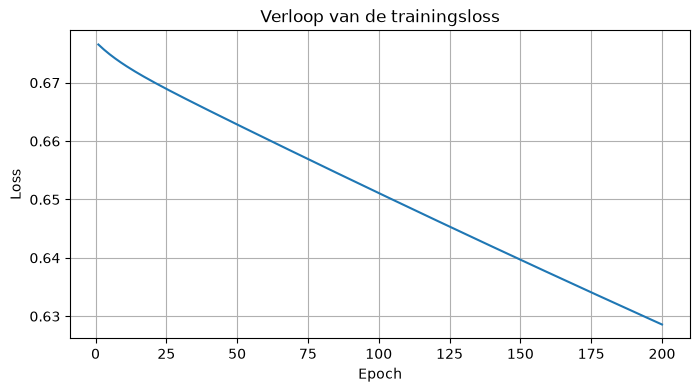

In [23]:

import matplotlib.pyplot as plt

# Grafiek maken
plt.figure(figsize=(8, 4))

# Loss per epoch tekenen
plt.plot(range(1, len(train_losses) + 1), train_losses)

# Titel en assen
plt.title("Verloop van de trainingsloss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

# Raster toevoegen
plt.grid(True)

# Grafiek weergeven
plt.show()



## 14. Trainingsresultaten controleren

Een dalende loss betekent niet automatisch dat alle voorspellingen correct zijn.

We berekenen daarom de voorspelde klasse voor ieder trainingsvoorbeeld en vergelijken deze met het juiste label.

Een kans van 0,5 of hoger betekent klasse 1. Een lagere kans betekent klasse 0.


In [24]:

# Voorspellingen berekenen
with torch.no_grad():
    scores = model(training_features_geschaald)
    kansen = torch.sigmoid(scores)
    voorspellingen = (kansen >= 0.5).float()

# Aantal correcte voorspellingen
correct = (voorspellingen == training_labels).sum().item()
totaal = len(training_labels)

# Resultaat weergeven
for i in range(totaal):
    print(f"Voorbeeld {i + 1}: "
          f"Voorspeld = {int(voorspellingen[i].item())}, "
          f"Juist = {int(training_labels[i].item())}")

print(f"\nAccuracy: {correct}/{totaal} = {correct/totaal*100:.1f}%")


Voorbeeld 1: Voorspeld = 0, Juist = 0
Voorbeeld 2: Voorspeld = 0, Juist = 0
Voorbeeld 3: Voorspeld = 1, Juist = 0
Voorbeeld 4: Voorspeld = 1, Juist = 1
Voorbeeld 5: Voorspeld = 1, Juist = 1
Voorbeeld 6: Voorspeld = 1, Juist = 1

Accuracy: 5/6 = 83.3%



### Conclusie

Na 200 epochs voorspelt het model 5 van de 6 trainingsvoorbeelden correct. De accuracy is **83,3%**.

De loss is tijdens de training gedaald. Het model heeft dus geleerd, maar classificeert nog niet alle voorbeelden correct.

**Experimenteer zelf:**

- Verhoog of verlaag het aantal epochs.
- Verander de learning rate.
- Onderzoek wat er gebeurt als je meer trainingsvoorbeelden toevoegt.

**Onderzoeksvraag:** Leidt een lagere loss altijd tot een hogere accuracy?

Let op: de accuracy is berekend op de trainingsgegevens. Dit zegt nog niet hoe goed het model nieuwe, onbekende gegevens voorspelt.
